import libraries and load the data

In [24]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fakenews.csv")

df.head()

,news_id,headline,body_text,source,label
0,1,Global economy faces recession,The Prime Minister attended the inauguration c...,CNN,Real
1,2,"Earthquake hits Chittagong, panic spreads",Government sources state that an official anno...,Daily Star,Real
2,3,Breakthrough in Bangladesh's tech industry,Local administration has visited the spot for ...,BBC,Fake
3,4,Dengue situation worsens in the country,The Prime Minister attended the inauguration c...,BBC,Fake
4,5,New virus outbreak sparks fear,Government sources state that an official anno...,Reuters,Real


check numerical statistics

In [25]:
def extract_numbers(text):
    if pd.isna(text):
        return []
    return re.findall(r'\b\d+(?:\.\d+)?%?\b', str(text))

df['numbers'] = df['body_text'].apply(extract_numbers)

df['number_count'] = df['numbers'].apply(len)

df[['news_id', 'label', 'numbers', 'number_count']].head(10)

,news_id,label,numbers,number_count
0,1,Real,[],0
1,2,Real,[],0
2,3,Fake,[],0
3,4,Fake,[],0
4,5,Real,[],0
5,6,Fake,[],0
6,7,Fake,[],0
7,8,Real,[],0
8,9,Fake,[],0
9,10,Real,[],0


 Analyse Misleading or Unsupported Statistics

In [26]:
df['has_statistics'] = df['number_count'] > 0

print("Statistics found:")
print(df.groupby('label')['has_statistics'].sum())

print("\nAverage number of statistics:")
print(df.groupby('label')['number_count'].mean())

Statistics found:
label
Fake    0
Real    0
Name: has_statistics, dtype: int64

Average number of statistics:
label
Fake    0.0
Real    0.0
Name: number_count, dtype: float64



Detect Manipulated or Inconsistent Headlines

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df['combined_text'] = df['headline'].fillna('') + " " + df['body_text'].fillna('')

vectorizer = TfidfVectorizer(stop_words='english')

tfidf = vectorizer.fit_transform(df['combined_text'])

similarity_scores = []

for i in range(len(df)):
    headline = vectorizer.transform([str(df.iloc[i]['headline'])])
    body = vectorizer.transform([str(df.iloc[i]['body_text'])])

    score = cosine_similarity(headline, body)[0][0]
    similarity_scores.append(score)

df['headline_body_similarity'] = similarity_scores

df[['headline', 'body_text', 'label', 'headline_body_similarity']].head(10)

,headline,body_text,label,headline_body_similarity
0,Global economy faces recession,The Prime Minister attended the inauguration c...,Real,0.0
1,"Earthquake hits Chittagong, panic spreads",Government sources state that an official anno...,Real,0.0
2,Breakthrough in Bangladesh's tech industry,Local administration has visited the spot for ...,Fake,0.0
3,Dengue situation worsens in the country,The Prime Minister attended the inauguration c...,Fake,0.0
4,New virus outbreak sparks fear,Government sources state that an official anno...,Real,0.0
5,"Earthquake hits Chittagong, panic spreads",Doctors advise that basic precautions can help...,Fake,0.0
6,Global economy faces recession,Government sources state that an official anno...,Fake,0.0
7,Global economy faces recession,"Many are calling it a conspiracy. However, exp...",Real,0.0
8,"Earthquake hits Chittagong, panic spreads",Doctors advise that basic precautions can help...,Fake,0.0
9,New curriculum introduced in schools,Incidents were reported from various parts of ...,Real,0.0


Identify Unreliable Sources

In [28]:
df['source'] = df['source'].fillna('Unknown')

unreliable_sources = ['Unknown News', 'Unknown', '']

df['unreliable_source'] = df['source'].isin(unreliable_sources)

print(df.groupby('label')['unreliable_source'].sum())

print("\nUnreliable source articles:")
display(df[df['unreliable_source']][['news_id', 'source', 'label']])

label
Fake    196
Real    227
Name: unreliable_source, dtype: int64

Unreliable source articles:


,news_id,source,label
8,9,Unknown News,Fake
10,11,Unknown News,Fake
16,17,Unknown News,Fake
20,21,Unknown News,Fake
24,25,Unknown News,Real
...,...,...,...
2207,2208,Unknown News,Real
2208,2209,Unknown News,Real
2209,2210,Unknown News,Fake
2210,2211,Unknown News,Real


Compare Fake and Real News

In [29]:
analysis = df.groupby('label').agg({
    'number_count': 'mean',
    'headline_body_similarity': 'mean',
    'unreliable_source': 'sum'
})

print(analysis)

       number_count  headline_body_similarity  unreliable_source
label                                                           
Fake            0.0                  0.000573                196
Real            0.0                  0.000808                227


Visualisation

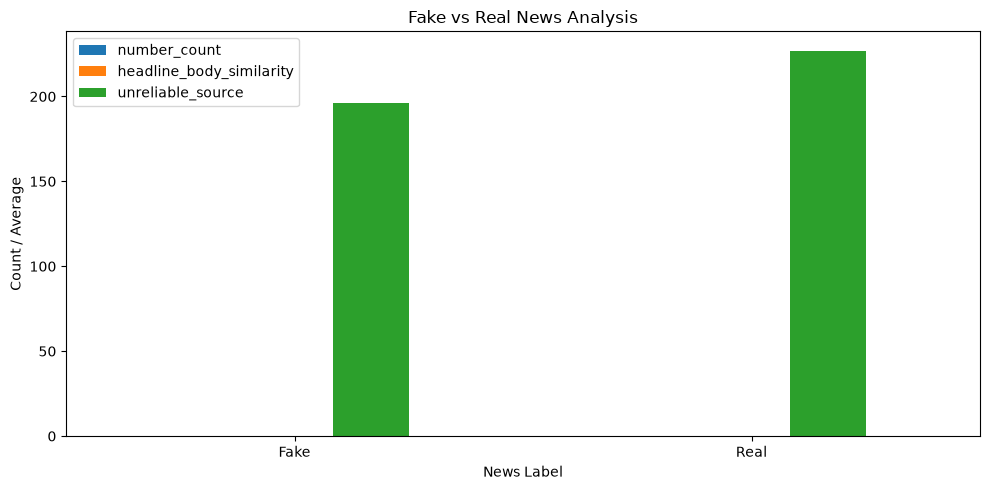

In [30]:
analysis.plot(kind='bar', figsize=(10, 5))

plt.title('Fake vs Real News Analysis')
plt.xlabel('News Label')
plt.ylabel('Count / Average')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

Final Result

In [31]:
print("Misleading Statistics, Manipulated Data and Unreliable Citations Analysis")

print("\nTotal Articles:", len(df))

print("Articles Containing Numbers:", df['has_statistics'].sum())

print("Articles with Unreliable Sources:", df['unreliable_source'].sum())

print("Average Headline-Body Similarity:",
      round(df['headline_body_similarity'].mean(), 3))

print("\nFake vs Real Analysis:")
print(analysis)

Misleading Statistics, Manipulated Data and Unreliable Citations Analysis

Total Articles: 2212
Articles Containing Numbers: 0
Articles with Unreliable Sources: 423
Average Headline-Body Similarity: 0.001

Fake vs Real Analysis:
       number_count  headline_body_similarity  unreliable_source
label                                                           
Fake            0.0                  0.000573                196
Real            0.0                  0.000808                227
